In [2]:
# Import MongoDB client
from pymongo import MongoClient

# Connect to local MongoDB server
client = MongoClient("mongodb://localhost:27017/")

# Test database connection
try:
    client.admin.command("ping")
    print("MongoDB Connected Successfully!")

except Exception as e:
    print("MongoDB Connection Failed:", e)

MongoDB Connected Successfully!


In [3]:
# Select Hospital Database
db = client["hospital_analysis"]

# Display database name
print("Database Name:", db.name)

# Check existing collections
print("Existing Collections:", db.list_collection_names())

Database Name: hospital_analysis
Existing Collections: []


In [4]:
import os

# Set dataset folder path
data_folder = "../Data"

# List all downloaded files
files = os.listdir(data_folder)

print("Files found in Data folder:")

for file in files:
    print(file)

Files found in Data folder:
HospitalOPD


In [5]:
import pandas as pd

# Load hospital dataset
file_path = "../Data/HospitalOPD/HospitalOPD-noname.csv"

df = pd.read_csv(file_path)

# Display basic information
print("Dataset Loaded Successfully!")
print("Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())


Dataset Loaded Successfully!
Shape: (62422, 25)

First 5 Records:


,record_no,patient_id,Unnamed: 2,appointment_id,appointment_start_datetime,prescription_doctor_id,prescription_doctor_name,prescription_order_id,prescription_start_datetime,prescription_end_datetime,...,imaging_result_id,imaging_name,imaging_start_datetime,imaging_end_datetime,pharmacy_sale_line_id,medicine_name,pharmacy_start_datetime,pharmacy_end_datetime,flow_code,flow_name
0,1,10,NaN,445911,3/30/2026 5:36,225,Admin,106357,3/30/2026 5:38,3/30/2026 6:48,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription
1,2,57,NaN,335085,10/14/2025 5:23,193,Dr. Abrar Ahmed Bhatti,43515,10/14/2025 5:39,10/14/2025 5:53,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription
2,3,57,NaN,335085,10/14/2025 5:23,193,Dr. Abrar Ahmed Bhatti,43541,10/14/2025 6:11,10/14/2025 6:24,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription
3,4,60,NaN,322358,9/25/2025 13:36,195,Dr. Anique Ahmed,34654,9/25/2025 13:50,9/25/2025 13:51,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription
4,5,72,NaN,337714,10/17/2025 6:40,202,Dr. Mehreen Batool Bokhari,45263,10/17/2025 6:49,10/17/2025 6:49,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription


In [6]:
# Display all column names with their data types

print("TOTAL COLUMNS:", len(df.columns))
print("\nCOLUMN DETAILS:\n")

for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}  -->  {df[col].dtype}")

TOTAL COLUMNS: 25

COLUMN DETAILS:

1. record_no  -->  int64
2. patient_id  -->  int64
3. Unnamed: 2  -->  float64
4. appointment_id  -->  int64
5. appointment_start_datetime  -->  object
6. prescription_doctor_id  -->  int64
7. prescription_doctor_name  -->  object
8. prescription_order_id  -->  int64
9. prescription_start_datetime  -->  object
10. prescription_end_datetime  -->  object
11. lab_id  -->  float64
12. lab_name  -->  object
13. lab_start_datetime  -->  object
14. lab_end_datetime  -->  object
15. imaging_request_id  -->  float64
16. imaging_result_id  -->  float64
17. imaging_name  -->  object
18. imaging_start_datetime  -->  object
19. imaging_end_datetime  -->  object
20. pharmacy_sale_line_id  -->  float64
21. medicine_name  -->  object
22. pharmacy_start_datetime  -->  object
23. pharmacy_end_datetime  -->  object
24. flow_code  -->  int64
25. flow_name  -->  object


In [7]:
# Check missing values in every column

missing_data = pd.DataFrame({
    "Column": df.columns,
    "Missing Values": df.isnull().sum().values,
    "Missing Percentage": (df.isnull().sum().values / len(df)) * 100
})

display(
    missing_data.sort_values(
        by="Missing Percentage",
        ascending=False
    ).reset_index(drop=True)
)

,Column,Missing Values,Missing Percentage
0,Unnamed: 2,62422,100.000000
1,pharmacy_end_datetime,62120,99.516196
2,pharmacy_start_datetime,62120,99.516196
3,medicine_name,62120,99.516196
4,pharmacy_sale_line_id,62120,99.516196
5,imaging_end_datetime,56909,91.168178
6,imaging_name,56899,91.152158
7,imaging_result_id,56899,91.152158
8,imaging_start_datetime,56899,91.152158
9,imaging_request_id,56899,91.152158


In [8]:
# Explore hospital workflow categories

print("Unique Flow Names:")
print(df["flow_name"].unique())

print("\nFlow Name Distribution:")

flow_distribution = (
    df["flow_name"]
    .value_counts()
    .reset_index()
)

flow_distribution.columns = ["Flow Name", "Record Count"]

flow_distribution["Percentage"] = (
    flow_distribution["Record Count"] / len(df) * 100
)

display(flow_distribution)

Unique Flow Names:
['Appointment → Prescription' 'Appointment → Prescription → Lab'
 'Appointment → Prescription → Imaging'
 'Appointment → Prescription → Lab + Imaging'
 'Appointment → Prescription → Pharmacy'
 'Appointment → Prescription → Lab + Pharmacy'
 'Appointment → Prescription → Imaging + Pharmacy']

Flow Name Distribution:


,Flow Name,Record Count,Percentage
0,Appointment → Prescription,40164,64.342700
1,Appointment → Prescription → Lab,16434,26.327256
2,Appointment → Prescription → Imaging,3947,6.323091
3,Appointment → Prescription → Lab + Imaging,1575,2.523149
4,Appointment → Prescription → Pharmacy,281,0.450162
5,Appointment → Prescription → Lab + Pharmacy,20,0.032040
6,Appointment → Prescription → Imaging + Pharmacy,1,0.001602


In [9]:
# Basic dataset statistics

print("TOTAL RECORDS:", len(df))

print("\nUNIQUE COUNTS:")
print("Unique Patients:", df["patient_id"].nunique())
print("Unique Appointments:", df["appointment_id"].nunique())
print("Unique Doctors:", df["prescription_doctor_id"].nunique())
print("Unique Prescriptions:", df["prescription_order_id"].nunique())

# Convert appointment datetime into datetime format
df["appointment_start_datetime"] = pd.to_datetime(
    df["appointment_start_datetime"],
    errors="coerce"
)

print("\nAPPOINTMENT DATE RANGE:")
print("Earliest Date:", df["appointment_start_datetime"].min())
print("Latest Date:", df["appointment_start_datetime"].max())

TOTAL RECORDS: 62422

UNIQUE COUNTS:
Unique Patients: 39442
Unique Appointments: 49912
Unique Doctors: 98
Unique Prescriptions: 50568

APPOINTMENT DATE RANGE:
Earliest Date: 2024-04-25 11:12:00
Latest Date: 2026-04-07 08:03:00


In [11]:
# Check duplicate records

print("Duplicate Rows:", df.duplicated().sum())

print("\nDuplicate Record Numbers:", 
      df["record_no"].duplicated().sum())

print("Duplicate Appointment IDs:",
      df["appointment_id"].duplicated().sum())

print("Duplicate Patient IDs:",
      df["patient_id"].duplicated().sum())

print("Duplicate Prescription IDs:",
      df["prescription_order_id"].duplicated().sum())

Duplicate Rows: 0

Duplicate Record Numbers: 0
Duplicate Appointment IDs: 12510
Duplicate Patient IDs: 22980
Duplicate Prescription IDs: 11854


In [12]:
print("Exact Duplicate Rows:", df.duplicated().sum())

Exact Duplicate Rows: 0


In [13]:
# Find appointments having multiple records

appointment_counts = (
    df["appointment_id"]
    .value_counts()
)

print("Appointments with multiple records:",
      (appointment_counts > 1).sum())

print("\nTop 10 repeated appointment IDs:")
display(appointment_counts.head(10).to_frame(
    name="Record Count"
))

# Inspect one repeated appointment
sample_id = appointment_counts[
    appointment_counts > 1
].index[0]

print("\nSample Appointment ID:", sample_id)

display(
    df[df["appointment_id"] == sample_id]
)

Appointments with multiple records: 4822

Top 10 repeated appointment IDs:


,Record Count
appointment_id,
427909,28
424659,28
333459,26
381284,24
423497,23
411348,23
424643,23
326726,23
375908,22



Sample Appointment ID: 427909


,record_no,patient_id,Unnamed: 2,appointment_id,appointment_start_datetime,prescription_doctor_id,prescription_doctor_name,prescription_order_id,prescription_start_datetime,prescription_end_datetime,...,imaging_result_id,imaging_name,imaging_start_datetime,imaging_end_datetime,pharmacy_sale_line_id,medicine_name,pharmacy_start_datetime,pharmacy_end_datetime,flow_code,flow_name
7747,7748,54445,NaN,427909,2026-02-26 05:37:00,179,Dr. Ehsan-Ul-Haq,97669,2/26/2026 5:55,2/26/2026 5:55,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,Appointment → Prescription → Lab
7748,7749,54445,NaN,427909,2026-02-26 05:37:00,179,Dr. Ehsan-Ul-Haq,97669,2/26/2026 5:55,2/26/2026 5:55,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,Appointment → Prescription → Lab
7749,7750,54445,NaN,427909,2026-02-26 05:37:00,179,Dr. Ehsan-Ul-Haq,97669,2/26/2026 5:55,2/26/2026 5:55,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,Appointment → Prescription → Lab
7750,7751,54445,NaN,427909,2026-02-26 05:37:00,179,Dr. Ehsan-Ul-Haq,97669,2/26/2026 5:55,2/26/2026 5:55,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,Appointment → Prescription → Lab
7751,7752,54445,NaN,427909,2026-02-26 05:37:00,179,Dr. Ehsan-Ul-Haq,97669,2/26/2026 5:55,2/26/2026 5:55,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,Appointment → Prescription → Lab
7752,7753,54445,NaN,427909,2026-02-26 05:37:00,179,Dr. Ehsan-Ul-Haq,97669,2/26/2026 5:55,2/26/2026 5:55,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,Appointment → Prescription → Lab
7753,7754,54445,NaN,427909,2026-02-26 05:37:00,179,Dr. Ehsan-Ul-Haq,97669,2/26/2026 5:55,2/26/2026 5:55,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,Appointment → Prescription → Lab
7754,7755,54445,NaN,427909,2026-02-26 05:37:00,179,Dr. Ehsan-Ul-Haq,97669,2/26/2026 5:55,2/26/2026 5:55,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,Appointment → Prescription → Lab
7755,7756,54445,NaN,427909,2026-02-26 05:37:00,179,Dr. Ehsan-Ul-Haq,97669,2/26/2026 5:55,2/26/2026 5:55,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,Appointment → Prescription → Lab
7756,7757,54445,NaN,427909,2026-02-26 05:37:00,179,Dr. Ehsan-Ul-Haq,97669,2/26/2026 5:55,2/26/2026 5:55,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,Appointment → Prescription → Lab


In [14]:
# Inspect relevant columns for the sample appointment

sample_data = df[df["appointment_id"] == sample_id]

columns_to_check = [
    "record_no",
    "patient_id",
    "appointment_id",
    "prescription_order_id",
    "lab_id",
    "lab_name",
    "imaging_request_id",
    "imaging_result_id",
    "imaging_name",
    "pharmacy_sale_line_id",
    "medicine_name",
    "flow_name"
]

display(sample_data[columns_to_check])

,record_no,patient_id,appointment_id,prescription_order_id,lab_id,lab_name,imaging_request_id,imaging_result_id,imaging_name,pharmacy_sale_line_id,medicine_name,flow_name
7747,7748,54445,427909,97669,213790.0,Complete Blood Count,NaN,NaN,NaN,NaN,NaN,Appointment → Prescription → Lab
7748,7749,54445,427909,97669,213791.0,ESR,NaN,NaN,NaN,NaN,NaN,Appointment → Prescription → Lab
7749,7750,54445,427909,97669,213792.0,TSH,NaN,NaN,NaN,NaN,NaN,Appointment → Prescription → Lab
7750,7751,54445,427909,97669,213793.0,Renal Function Tests (RFTs),NaN,NaN,NaN,NaN,NaN,Appointment → Prescription → Lab
7751,7752,54445,427909,97669,213794.0,Serum Calcium,NaN,NaN,NaN,NaN,NaN,Appointment → Prescription → Lab
7752,7753,54445,427909,97669,213795.0,Phosphorus,NaN,NaN,NaN,NaN,NaN,Appointment → Prescription → Lab
7753,7754,54445,427909,97669,213797.0,25-OH Vitamin D,NaN,NaN,NaN,NaN,NaN,Appointment → Prescription → Lab
7754,7755,54445,427909,97669,213802.0,Complete Blood Count,NaN,NaN,NaN,NaN,NaN,Appointment → Prescription → Lab
7755,7756,54445,427909,97669,213803.0,ESR,NaN,NaN,NaN,NaN,NaN,Appointment → Prescription → Lab
7756,7757,54445,427909,97669,213804.0,TSH,NaN,NaN,NaN,NaN,NaN,Appointment → Prescription → Lab


In [15]:
# Count service records for the sample appointment

print("Sample Appointment:", sample_id)
print("Total Records:", len(sample_data))

print("\nService Record Counts:")

print(
    "Lab Records:",
    sample_data["lab_id"].notna().sum()
)

print(
    "Imaging Records:",
    sample_data["imaging_request_id"].notna().sum()
)

print(
    "Pharmacy Records:",
    sample_data["pharmacy_sale_line_id"].notna().sum()
)

print(
    "Unique Lab Names:",
    sample_data["lab_name"].nunique()
)

print(
    "Unique Imaging Names:",
    sample_data["imaging_name"].nunique()
)

print(
    "Unique Medicines:",
    sample_data["medicine_name"].nunique()
)

Sample Appointment: 427909
Total Records: 28

Service Record Counts:
Lab Records: 28
Imaging Records: 0
Pharmacy Records: 0
Unique Lab Names: 7
Unique Imaging Names: 0
Unique Medicines: 0


In [16]:
# Analyse laboratory records for sample appointment

lab_analysis = (
    sample_data.groupby("lab_name")
    .agg(
        Total_Records=("lab_id", "count"),
        Unique_Lab_IDs=("lab_id", "nunique")
    )
    .reset_index()
)

print("Laboratory-wise Analysis:")
display(lab_analysis)

print("\nTotal Unique Lab IDs:",
      sample_data["lab_id"].nunique())

Laboratory-wise Analysis:


,lab_name,Total_Records,Unique_Lab_IDs
0,25-OH Vitamin D,4,2
1,Complete Blood Count,4,2
2,ESR,4,2
3,Phosphorus,4,2
4,Renal Function Tests (RFTs),4,2
5,Serum Calcium,4,2
6,TSH,4,2



Total Unique Lab IDs: 14


In [17]:
# Overall hospital service analysis

service_summary = pd.DataFrame({
    "Service": ["Laboratory", "Imaging", "Pharmacy"],

    "Total Records": [
        df["lab_id"].notna().sum(),
        df["imaging_request_id"].notna().sum(),
        df["pharmacy_sale_line_id"].notna().sum()
    ],

    "Unique IDs": [
        df["lab_id"].nunique(),
        df["imaging_request_id"].nunique(),
        df["pharmacy_sale_line_id"].nunique()
    ],

    "Unique Names": [
        df["lab_name"].nunique(),
        df["imaging_name"].nunique(),
        df["medicine_name"].nunique()
    ]
})

display(service_summary)

,Service,Total Records,Unique IDs,Unique Names
0,Laboratory,18029,17083,119
1,Imaging,5523,5360,38
2,Pharmacy,302,262,154


In [18]:
# Most frequently recorded hospital services

print("TOP 10 LAB TESTS")
display(df["lab_name"].value_counts().head(10).to_frame("Count"))

print("\nTOP 10 IMAGING SERVICES")
display(df["imaging_name"].value_counts().head(10).to_frame("Count"))

print("\nTOP 10 MEDICINES")
display(df["medicine_name"].value_counts().head(10).to_frame("Count"))

TOP 10 LAB TESTS


,Count
lab_name,
Complete Blood Count,5216
Urine R/E,1834
TSH,754
Liver Function Test,751
Glycosylated Hb (HbA1c),735
Renal Function Tests (RFTs),678
HCV Ab by ICT,624
HBsAg By ICT,602
Glucose Random,485



TOP 10 IMAGING SERVICES


,Count
imaging_name,
FWB,2298
pelvis(Ultrasound),1369
Abdomen Ultrasound,543
Anomaly-Fetal,411
Abdomen & Pelvis,180
KUB Ultrasound,128
Doppler Fetal,127
TVS-Vaginal,75
N T Scan,68



TOP 10 MEDICINES


,Count
medicine_name,
Histazolin Eye Drop - 5 mL OP,11
Lotepred-T 0.5/0.3 % Eye Drop - 5 mL MTH,10
Soda Glycerine Ear Drop - 10 mL MTH,6
Nospa 40mg Tablet -MTH,6
Tears Forte Eye Drop - 15 mL OP,6
Risek 40 mg Inf - 1 Vial IV MTH,6
Panadol Tab 500 mg,5
Jikoside 4mg cap-20s,5
Jikoside 4mg/2ml inj 5s,5


In [19]:
print("TOP 10 MEDICINES")

medicine_counts = (
    df["medicine_name"]
    .value_counts()
    .head(10)
    .reset_index()
)

medicine_counts.columns = ["Medicine Name", "Count"]

display(medicine_counts)

TOP 10 MEDICINES


,Medicine Name,Count
0,Histazolin Eye Drop - 5 mL OP,11
1,Lotepred-T 0.5/0.3 % Eye Drop - 5 mL MTH,10
2,Soda Glycerine Ear Drop - 10 mL MTH,6
3,Nospa 40mg Tablet -MTH,6
4,Tears Forte Eye Drop - 15 mL OP,6
5,Risek 40 mg Inf - 1 Vial IV MTH,6
6,Panadol Tab 500 mg,5
7,Jikoside 4mg cap-20s,5
8,Jikoside 4mg/2ml inj 5s,5
9,Voren 75 mg/mL Inj - 100 Ampx3 mL,5


In [20]:
# Monthly appointment analysis

df["appointment_month"] = (
    df["appointment_start_datetime"]
    .dt.to_period("M")
)

monthly_appointments = (
    df.groupby("appointment_month")["appointment_id"]
    .nunique()
    .reset_index(name="Total Appointments")
)

monthly_appointments["appointment_month"] = (
    monthly_appointments["appointment_month"].astype(str)
)

display(monthly_appointments)

,appointment_month,Total Appointments
0,2024-04,4
1,2024-05,2
2,2024-06,2
3,2024-07,2
4,2024-08,1
5,2024-10,1
6,2024-11,1
7,2024-12,3
8,2025-02,4
9,2025-03,27


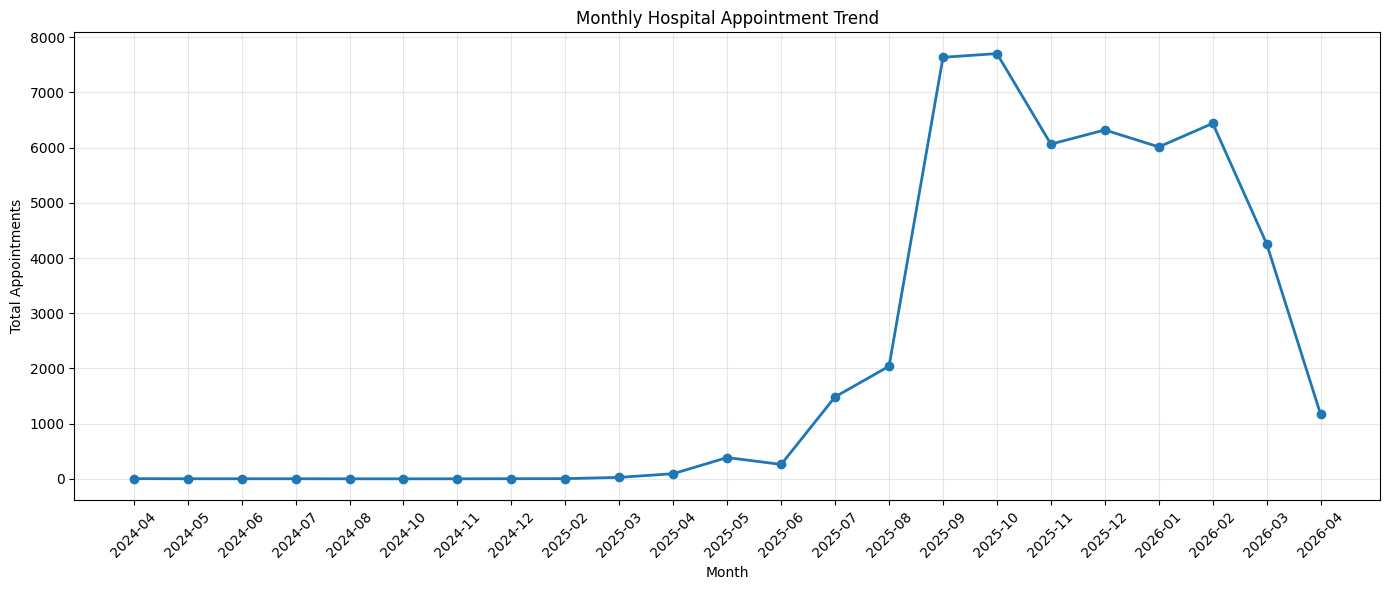

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_appointments["appointment_month"],
    monthly_appointments["Total Appointments"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Hospital Appointment Trend")
plt.xlabel("Month")
plt.ylabel("Total Appointments")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
# Find patients with the highest number of appointments

patient_activity = (
    df.groupby("patient_id")["appointment_id"]
    .nunique()
    .reset_index(name="Total Appointments")
    .sort_values(
        by="Total Appointments",
        ascending=False
    )
    .head(10)
)

print("TOP 10 MOST ACTIVE PATIENTS")
display(patient_activity)

TOP 10 MOST ACTIVE PATIENTS


,patient_id,Total Appointments
635,7349,11
16814,229605,10
18377,240943,10
15685,219392,10
20400,247164,10
18369,240914,10
15684,219376,9
9734,126850,9
14447,203534,9
15582,218253,9


In [23]:
# Patient visit frequency distribution

patient_visits = (
    df.groupby("patient_id")["appointment_id"]
    .nunique()
)

visit_distribution = (
    patient_visits
    .value_counts()
    .sort_index()
    .reset_index()
)

visit_distribution.columns = [
    "Number of Appointments",
    "Number of Patients"
]

print("PATIENT VISIT FREQUENCY")
display(visit_distribution)

print("\nPATIENT SUMMARY")
print("Total Unique Patients:", patient_visits.count())
print("One-time Patients:", (patient_visits == 1).sum())
print("Returning Patients:", (patient_visits > 1).sum())

PATIENT VISIT FREQUENCY


,Number of Appointments,Number of Patients
0,1,32322
1,2,5067
2,3,1317
3,4,434
4,5,169
5,6,65
6,7,32
7,8,21
8,9,9
9,10,5



PATIENT SUMMARY
Total Unique Patients: 39442
One-time Patients: 32322
Returning Patients: 7120


In [24]:
# Identify all datetime columns

datetime_columns = [
    "appointment_start_datetime",
    "prescription_start_datetime",
    "prescription_end_datetime",
    "lab_start_datetime",
    "lab_end_datetime",
    "imaging_start_datetime",
    "imaging_end_datetime",
    "pharmacy_start_datetime",
    "pharmacy_end_datetime"
]

# Check missing and invalid date values
date_quality = []

for col in datetime_columns:

    parsed_dates = pd.to_datetime(
        df[col],
        errors="coerce"
    )

    invalid_dates = (
        df[col].notna() & parsed_dates.isna()
    ).sum()

    date_quality.append({
        "Column": col,
        "Missing Values": df[col].isna().sum(),
        "Invalid Dates": invalid_dates
    })

date_quality_df = pd.DataFrame(date_quality)

display(date_quality_df)

,Column,Missing Values,Invalid Dates
0,appointment_start_datetime,0,0
1,prescription_start_datetime,12,0
2,prescription_end_datetime,1,0
3,lab_start_datetime,44393,0
4,lab_end_datetime,44393,4702
5,imaging_start_datetime,56899,0
6,imaging_end_datetime,56909,0
7,pharmacy_start_datetime,62120,0
8,pharmacy_end_datetime,62120,0


In [25]:
# Identify invalid lab end datetime values
invalid_lab_end = df.loc[
    df["lab_end_datetime"].notna() &
    pd.to_datetime(df["lab_end_datetime"], errors="coerce").isna(),
    "lab_end_datetime"
]

print("Total Invalid Lab End Dates:", len(invalid_lab_end))

print("\nTop 20 Invalid Values:")
display(invalid_lab_end.value_counts().head(20))

Total Invalid Lab End Dates: 4702

Top 20 Invalid Values:


lab_end_datetime
35:06.0    12
07:32.0    12
55:26.0    11
42:00.0    10
17:50.0    10
30:47.0    10
26:32.0     9
37:06.0     9
15:35.0     9
01:53.0     9
51:31.0     9
38:31.0     9
28:57.0     9
51:45.0     9
14:02.0     8
33:22.0     8
15:25.0     8
10:56.0     8
56:58.0     8
13:18.0     8
Name: count, dtype: int64

In [26]:
# Inspect lab start and end datetime values
lab_samples = df.loc[
    df["lab_end_datetime"].notna(),
    ["lab_start_datetime", "lab_end_datetime"]
].head(20)

display(lab_samples)

,lab_start_datetime,lab_end_datetime
10,9/18/2025 14:30,9/18/2025 15:18
11,9/18/2025 14:30,9/26/2025 18:44
12,9/18/2025 14:30,9/18/2025 15:15
29,2/10/2026 8:13,2/10/2026 9:11
30,2/10/2026 8:13,2/10/2026 9:07
31,2/10/2026 8:13,2/10/2026 9:11
59,9/12/2025 7:49,9/12/2025 10:54
60,9/12/2025 7:49,9/12/2025 10:45
69,9/29/2025 14:31,9/29/2025 15:41
82,10/18/2025 15:08,10/18/2025 16:27


In [27]:
# Find records where lab end datetime is invalid
parsed_lab_end = pd.to_datetime(
    df["lab_end_datetime"],
    errors="coerce"
)

invalid_lab_records = df.loc[
    df["lab_end_datetime"].notna() &
    parsed_lab_end.isna(),
    [
        "record_no",
        "appointment_id",
        "lab_name",
        "lab_start_datetime",
        "lab_end_datetime"
    ]
]

print("Invalid Lab End Records:", len(invalid_lab_records))

print("\nLab Start Date Missing:")
print(invalid_lab_records["lab_start_datetime"].isna().sum())

print("\nSample Invalid Records:")
display(invalid_lab_records.head(20))

Invalid Lab End Records: 4702

Lab Start Date Missing:
0

Sample Invalid Records:


,record_no,appointment_id,lab_name,lab_start_datetime,lab_end_datetime
4001,4002,318981,Complete Blood Count,9/21/2025 5:50,53:45.0
4002,4003,318981,DENGUE NS1,9/21/2025 5:50,46:40.0
4003,4004,320263,Complete Blood Count,9/23/2025 6:01,29:40.0
4011,4012,391364,Urine for Culture & Sensitivy,1/3/2026 11:29,15:00.0
4046,4047,430370,Thyroid Profile (T3-FT4-TSH),3/2/2026 9:15,52:53.0
4061,4062,402421,Glycosylated Hb (HbA1c),1/20/2026 15:20,01:29.0
4062,4063,402421,Urine R/E,1/20/2026 15:20,59:04.0
4063,4064,402421,Urine for Culture & Sensitivy,1/20/2026 15:20,13:03.0
4103,4104,378604,Complete Blood Count,12/14/2025 11:04,22:59.0
4118,4119,450680,Complete Blood Count,4/5/2026 15:28,49:38.0


In [28]:
# Create a separate copy for data cleaning
df_clean = df.copy()

# Convert all datetime columns safely
datetime_columns = [
    "appointment_start_datetime",
    "prescription_start_datetime",
    "prescription_end_datetime",
    "lab_start_datetime",
    "lab_end_datetime",
    "imaging_start_datetime",
    "imaging_end_datetime",
    "pharmacy_start_datetime",
    "pharmacy_end_datetime"
]

for col in datetime_columns:
    df_clean[col] = pd.to_datetime(
        df_clean[col],
        errors="coerce"
    )

print("Original Records:", len(df))
print("Cleaned Records:", len(df_clean))

print("\nLab End Date Missing After Conversion:")
print(df_clean["lab_end_datetime"].isna().sum())

Original Records: 62422
Cleaned Records: 62422

Lab End Date Missing After Conversion:
49095


In [29]:
# Remove columns that contain only missing values
empty_columns = df_clean.columns[
    df_clean.isna().all()
].tolist()

print("Completely Empty Columns:", empty_columns)

df_clean.drop(columns=empty_columns, inplace=True)

print("\nUpdated Dataset Shape:", df_clean.shape)
print("Remaining Columns:", len(df_clean.columns))

Completely Empty Columns: ['Unnamed: 2']

Updated Dataset Shape: (62422, 25)
Remaining Columns: 25


In [30]:
print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)

print("\nRemaining Columns:")
for i, col in enumerate(df_clean.columns, start=1):
    print(i, "->", col)

Original Shape: (62422, 26)
Cleaned Shape: (62422, 25)

Remaining Columns:
1 -> record_no
2 -> patient_id
3 -> appointment_id
4 -> appointment_start_datetime
5 -> prescription_doctor_id
6 -> prescription_doctor_name
7 -> prescription_order_id
8 -> prescription_start_datetime
9 -> prescription_end_datetime
10 -> lab_id
11 -> lab_name
12 -> lab_start_datetime
13 -> lab_end_datetime
14 -> imaging_request_id
15 -> imaging_result_id
16 -> imaging_name
17 -> imaging_start_datetime
18 -> imaging_end_datetime
19 -> pharmacy_sale_line_id
20 -> medicine_name
21 -> pharmacy_start_datetime
22 -> pharmacy_end_datetime
23 -> flow_code
24 -> flow_name
25 -> appointment_month


In [31]:
# Missing value analysis of cleaned dataset
missing_summary = pd.DataFrame({
    "Column": df_clean.columns,
    "Missing Values": df_clean.isnull().sum().values,
    "Missing Percentage": (
        df_clean.isnull().mean().values * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_summary)

,Column,Missing Values,Missing Percentage
18,pharmacy_sale_line_id,62120,99.52
21,pharmacy_end_datetime,62120,99.52
20,pharmacy_start_datetime,62120,99.52
19,medicine_name,62120,99.52
17,imaging_end_datetime,56909,91.17
16,imaging_start_datetime,56899,91.15
15,imaging_name,56899,91.15
14,imaging_result_id,56899,91.15
13,imaging_request_id,56899,91.15
12,lab_end_datetime,49095,78.65


In [32]:
print("DATA TYPES OF ALL COLUMNS")
display(df.dtypes.to_frame(name="Data Type"))

print("\nSAMPLE DATA — FIRST 10 RECORDS")
display(df.head(10))

print("\nUNIQUE FLOW TYPES")
display(df[["flow_code", "flow_name"]].drop_duplicates())

DATA TYPES OF ALL COLUMNS


,Data Type
record_no,int64
patient_id,int64
Unnamed: 2,float64
appointment_id,int64
appointment_start_datetime,datetime64[ns]
prescription_doctor_id,int64
prescription_doctor_name,object
prescription_order_id,int64
prescription_start_datetime,object
prescription_end_datetime,object



SAMPLE DATA — FIRST 10 RECORDS


,record_no,patient_id,Unnamed: 2,appointment_id,appointment_start_datetime,prescription_doctor_id,prescription_doctor_name,prescription_order_id,prescription_start_datetime,prescription_end_datetime,...,imaging_name,imaging_start_datetime,imaging_end_datetime,pharmacy_sale_line_id,medicine_name,pharmacy_start_datetime,pharmacy_end_datetime,flow_code,flow_name,appointment_month
0,1,10,NaN,445911,2026-03-30 05:36:00,225,Admin,106357,3/30/2026 5:38,3/30/2026 6:48,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription,2026-03
1,2,57,NaN,335085,2025-10-14 05:23:00,193,Dr. Abrar Ahmed Bhatti,43515,10/14/2025 5:39,10/14/2025 5:53,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription,2025-10
2,3,57,NaN,335085,2025-10-14 05:23:00,193,Dr. Abrar Ahmed Bhatti,43541,10/14/2025 6:11,10/14/2025 6:24,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription,2025-10
3,4,60,NaN,322358,2025-09-25 13:36:00,195,Dr. Anique Ahmed,34654,9/25/2025 13:50,9/25/2025 13:51,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription,2025-09
4,5,72,NaN,337714,2025-10-17 06:40:00,202,Dr. Mehreen Batool Bokhari,45263,10/17/2025 6:49,10/17/2025 6:49,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription,2025-10
5,6,76,NaN,184952,2025-02-19 14:02:00,272,DR. AHMAD TAMIM BARYALAI,3510,2/19/2025 14:11,2/19/2025 14:33,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription,2025-02
6,7,81,NaN,307768,2025-09-07 05:59:00,387,Dr. Ambreen Naz,25567,9/7/2025 6:50,9/7/2025 7:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription,2025-09
7,8,81,NaN,358169,2025-11-17 05:42:00,191,Dr. Sohail Akbar,57053,11/17/2025 6:09,11/17/2025 6:09,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription,2025-11
8,9,85,NaN,372286,2025-12-05 15:27:00,530,Dr. Junaid Ul Hassan Khalid,64919,12/5/2025 15:40,12/5/2025 15:40,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription,2025-12
9,10,203,NaN,301697,2025-08-29 05:41:00,210,Dr. Abdul Nasir,22007,8/29/2025 5:44,8/29/2025 5:57,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription,2025-08



UNIQUE FLOW TYPES


,flow_code,flow_name
0,1,Appointment → Prescription
10,2,Appointment → Prescription → Lab
22,3,Appointment → Prescription → Imaging
87,5,Appointment → Prescription → Lab + Imaging
281,4,Appointment → Prescription → Pharmacy
5972,6,Appointment → Prescription → Lab + Pharmacy
42317,7,Appointment → Prescription → Imaging + Pharmacy


In [33]:
print("DUPLICATE RECORD ANALYSIS")

print("Total Records:", len(df))

print("Duplicate Complete Rows:", df.duplicated().sum())

print("Duplicate Record Numbers:", df["record_no"].duplicated().sum())

print("Duplicate Appointment IDs:", df["appointment_id"].duplicated().sum())

print("Duplicate Patient IDs:", df["patient_id"].duplicated().sum())

DUPLICATE RECORD ANALYSIS
Total Records: 62422
Duplicate Complete Rows: 0
Duplicate Record Numbers: 0
Duplicate Appointment IDs: 12510
Duplicate Patient IDs: 22980


In [34]:
# Remove completely empty column
df = df.drop(columns=["Unnamed: 2"], errors="ignore")

print("FINAL DATASET SUMMARY")
print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nRemaining Columns:")
print(df.columns.tolist())

print("\nDuplicate Complete Rows:", df.duplicated().sum())

FINAL DATASET SUMMARY
Total Records: 62422
Total Columns: 25

Remaining Columns:
['record_no', 'patient_id', 'appointment_id', 'appointment_start_datetime', 'prescription_doctor_id', 'prescription_doctor_name', 'prescription_order_id', 'prescription_start_datetime', 'prescription_end_datetime', 'lab_id', 'lab_name', 'lab_start_datetime', 'lab_end_datetime', 'imaging_request_id', 'imaging_result_id', 'imaging_name', 'imaging_start_datetime', 'imaging_end_datetime', 'pharmacy_sale_line_id', 'medicine_name', 'pharmacy_start_datetime', 'pharmacy_end_datetime', 'flow_code', 'flow_name', 'appointment_month']

Duplicate Complete Rows: 0


In [35]:
# Save cleaned dataset
cleaned_file_path = "../Data/HospitalOPD/cleaned_hospital_data.csv"

df.to_csv(cleaned_file_path, index=False)

print("Cleaned dataset saved successfully!")
print("File:", cleaned_file_path)
print("Records:", len(df))
print("Columns:", len(df.columns))

Cleaned dataset saved successfully!
File: ../Data/HospitalOPD/cleaned_hospital_data.csv
Records: 62422
Columns: 25


In [36]:
import os
import pandas as pd

file_path = "../Data/HospitalOPD/cleaned_hospital_data.csv"

print("File Exists:", os.path.exists(file_path))

saved_df = pd.read_csv(file_path)

print("Saved Dataset Shape:", saved_df.shape)
print("Total Records:", len(saved_df))
print("Total Columns:", len(saved_df.columns))

File Exists: True
Saved Dataset Shape: (62422, 25)
Total Records: 62422
Total Columns: 25


In [37]:
# Define collection names
collection_names = [
    "appointments",
    "prescriptions",
    "laboratory",
    "imaging",
    "pharmacy"
]

# Create collections if they do not already exist
existing_collections = db.list_collection_names()

for name in collection_names:
    if name not in existing_collections:
        db.create_collection(name)
        print(f"Created: {name}")
    else:
        print(f"Already Exists: {name}")

print("\nALL MONGODB COLLECTIONS:")
print(db.list_collection_names())

Created: appointments
Created: prescriptions
Created: laboratory
Created: imaging
Created: pharmacy

ALL MONGODB COLLECTIONS:
['pharmacy', 'prescriptions', 'laboratory', 'imaging', 'appointments']


In [38]:
# Select appointment-related columns
appointment_columns = [
    "appointment_id",
    "patient_id",
    "appointment_start_datetime",
    "flow_code",
    "flow_name",
    "appointment_month"
]

# Create unique appointment records
appointments_df = df[appointment_columns].drop_duplicates(
    subset=["appointment_id"]
).copy()

# Convert dates and missing values into MongoDB-friendly values
appointments_df["appointment_start_datetime"] = (
    appointments_df["appointment_start_datetime"].apply(
        lambda x: x.isoformat() if pd.notna(x) else None
    )
)

appointments_df["appointment_month"] = (
    appointments_df["appointment_month"].astype(str)
)

appointments_df = appointments_df.astype(object).where(
    pd.notna(appointments_df), None
)

# Convert DataFrame into MongoDB documents
appointment_records = appointments_df.to_dict("records")

# Insert records into MongoDB
if appointment_records:
    result = db["appointments"].insert_many(appointment_records)
    print("Appointments Inserted:", len(result.inserted_ids))

print("Total Documents in MongoDB:", db["appointments"].count_documents({}))

Appointments Inserted: 49912
Total Documents in MongoDB: 49912


In [39]:
# Verify appointment documents

print("Total Appointments:",
      db["appointments"].count_documents({}))

print("\nSample MongoDB Document:")

sample_appointment = db["appointments"].find_one(
    {},
    {"_id": 0}
)

display(sample_appointment)

Total Appointments: 49912

Sample MongoDB Document:


{'appointment_id': 445911,
 'patient_id': 10,
 'appointment_start_datetime': '2026-03-30T05:36:00',
 'flow_code': 1,
 'flow_name': 'Appointment → Prescription',
 'appointment_month': '2026-03'}

In [40]:
print("Total Appointments:",
      db["appointments"].count_documents({}))

print("\nSample MongoDB Document:")

sample_appointment = db["appointments"].find_one(
    {},
    {"_id": 0}
)

display(sample_appointment)

Total Appointments: 49912

Sample MongoDB Document:


{'appointment_id': 445911,
 'patient_id': 10,
 'appointment_start_datetime': '2026-03-30T05:36:00',
 'flow_code': 1,
 'flow_name': 'Appointment → Prescription',
 'appointment_month': '2026-03'}

In [41]:
print("Total Dataset Records:", len(df))

print("Missing Prescription IDs:",
      df["prescription_order_id"].isna().sum())

print("Unique Prescription IDs:",
      df["prescription_order_id"].nunique())

print("Duplicate Prescription IDs:",
      df["prescription_order_id"].duplicated().sum())

print("\nSample Prescription Records:")

display(
    df[
        [
            "appointment_id",
            "patient_id",
            "prescription_order_id",
            "prescription_doctor_id",
            "prescription_doctor_name",
            "prescription_start_datetime",
            "prescription_end_datetime"
        ]
    ].head()
)

Total Dataset Records: 62422
Missing Prescription IDs: 0
Unique Prescription IDs: 50568
Duplicate Prescription IDs: 11854

Sample Prescription Records:


,appointment_id,patient_id,prescription_order_id,prescription_doctor_id,prescription_doctor_name,prescription_start_datetime,prescription_end_datetime
0,445911,10,106357,225,Admin,3/30/2026 5:38,3/30/2026 6:48
1,335085,57,43515,193,Dr. Abrar Ahmed Bhatti,10/14/2025 5:39,10/14/2025 5:53
2,335085,57,43541,193,Dr. Abrar Ahmed Bhatti,10/14/2025 6:11,10/14/2025 6:24
3,322358,60,34654,195,Dr. Anique Ahmed,9/25/2025 13:50,9/25/2025 13:51
4,337714,72,45263,202,Dr. Mehreen Batool Bokhari,10/17/2025 6:49,10/17/2025 6:49


In [42]:
prescription_check = df.groupby("prescription_order_id").agg(
    total_rows=("prescription_order_id", "size"),
    unique_appointments=("appointment_id", "nunique"),
    unique_patients=("patient_id", "nunique"),
    unique_doctors=("prescription_doctor_id", "nunique")
)

print("Prescription IDs linked to multiple appointments:",
      (prescription_check["unique_appointments"] > 1).sum())

print("Prescription IDs linked to multiple patients:",
      (prescription_check["unique_patients"] > 1).sum())

print("Prescription IDs linked to multiple doctors:",
      (prescription_check["unique_doctors"] > 1).sum())

print("\nSample Repeated Prescription IDs:")
display(
    prescription_check[
        prescription_check["total_rows"] > 1
    ].head(10)
)

Prescription IDs linked to multiple appointments: 0
Prescription IDs linked to multiple patients: 0
Prescription IDs linked to multiple doctors: 0

Sample Repeated Prescription IDs:


,total_rows,unique_appointments,unique_patients,unique_doctors
prescription_order_id,,,,
3999,4,1,1,1
4074,4,1,1,1
4119,2,1,1,1
4203,2,1,1,1
4707,3,1,1,1
4711,4,1,1,1
4719,5,1,1,1
4792,3,1,1,1
4912,2,1,1,1


In [45]:
prescription_columns = [
    "prescription_order_id",
    "appointment_id",
    "patient_id",
    "prescription_doctor_id",
    "prescription_doctor_name",
    "prescription_start_datetime",
    "prescription_end_datetime"
]

prescriptions_df = df[prescription_columns].drop_duplicates(
    subset=["prescription_order_id"]
).copy()

# Convert dates into MongoDB-friendly strings
date_columns = [
    "prescription_start_datetime",
    "prescription_end_datetime"
]

for col in date_columns:
    prescriptions_df[col] = pd.to_datetime(
        prescriptions_df[col], errors="coerce"
    ).apply(lambda x: x.isoformat() if pd.notna(x) else None)

# Replace NaN with None
prescriptions_df = prescriptions_df.astype(object).where(
    pd.notna(prescriptions_df), None
)

prescription_records = prescriptions_df.to_dict("records")

print("Prepared Prescription Documents:", len(prescription_records))
print("Expected Unique Prescriptions:", df["prescription_order_id"].nunique())

print("\nSample Prescription Document:")
display(prescription_records[:2])

Prepared Prescription Documents: 50568
Expected Unique Prescriptions: 50568

Sample Prescription Document:


[{'prescription_order_id': 106357,
  'appointment_id': 445911,
  'patient_id': 10,
  'prescription_doctor_id': 225,
  'prescription_doctor_name': 'Admin',
  'prescription_start_datetime': '2026-03-30T05:38:00',
  'prescription_end_datetime': '2026-03-30T06:48:00'},
 {'prescription_order_id': 43515,
  'appointment_id': 335085,
  'patient_id': 57,
  'prescription_doctor_id': 193,
  'prescription_doctor_name': 'Dr. Abrar Ahmed Bhatti',
  'prescription_start_datetime': '2025-10-14T05:39:00',
  'prescription_end_datetime': '2025-10-14T05:53:00'}]

In [ ]:
prescriptions_collection = db["prescriptions"]

# Prevent duplicate insertion if the cell is run again
existing_count = prescriptions_collection.count_documents({})

if existing_count == 0:
    result = prescriptions_collection.insert_many(
        prescription_records
    )
    print("Prescriptions Inserted:", len(result.inserted_ids))
else:
    print("Insertion skipped!")
    print("Existing Documents:", existing_count)

print("Total Documents in MongoDB:",
      prescriptions_collection.count_documents({}))

Prescriptions Inserted: 50568
Total Documents in MongoDB: 50568


In [46]:
print("Total Laboratory Records:",
      df["lab_id"].notna().sum())

print("Missing Lab IDs:",
      df["lab_id"].isna().sum())

print("Unique Lab IDs:",
      df["lab_id"].nunique())

print("Unique Lab Names:",
      df["lab_name"].nunique())

# Check relationships of each Lab ID
lab_check = df[df["lab_id"].notna()].groupby("lab_id").agg(
    total_rows=("lab_id", "size"),
    unique_appointments=("appointment_id", "nunique"),
    unique_patients=("patient_id", "nunique"),
    unique_lab_names=("lab_name", "nunique")
)

print("\nLab IDs linked to multiple appointments:",
      (lab_check["unique_appointments"] > 1).sum())

print("Lab IDs linked to multiple patients:",
      (lab_check["unique_patients"] > 1).sum())

print("Lab IDs linked to multiple test names:",
      (lab_check["unique_lab_names"] > 1).sum())

print("\nSample Laboratory Records:")

display(
    df[
        [
            "appointment_id",
            "patient_id",
            "lab_id",
            "lab_name",
            "lab_start_datetime",
            "lab_end_datetime"
        ]
    ].dropna(subset=["lab_id"]).head()
)

Total Laboratory Records: 18029
Missing Lab IDs: 44393
Unique Lab IDs: 17083
Unique Lab Names: 119

Lab IDs linked to multiple appointments: 606
Lab IDs linked to multiple patients: 0
Lab IDs linked to multiple test names: 0

Sample Laboratory Records:


,appointment_id,patient_id,lab_id,lab_name,lab_start_datetime,lab_end_datetime
10,317127,203,127968.0,Complete Blood Count,9/18/2025 14:30,9/18/2025 15:18
11,317127,203,127969.0,Blood Culture & Sensitivity,9/18/2025 14:30,9/26/2025 18:44
12,317127,203,127970.0,ESR,9/18/2025 14:30,9/18/2025 15:15
29,416219,405,204667.0,Complete Blood Count,2/10/2026 8:13,2/10/2026 9:11
30,416219,405,204668.0,Urine R/E,2/10/2026 8:13,2/10/2026 9:07


In [47]:
lab_df = df.dropna(subset=["lab_id"]).copy()

lab_event_duplicates = lab_df.duplicated(
    subset=[
        "appointment_id",
        "lab_id",
        "lab_start_datetime",
        "lab_end_datetime"
    ],
    keep=False
)

print("Total Laboratory Records:", len(lab_df))

print("Potential Duplicate Lab Events:",
      lab_event_duplicates.sum())

print("\nSample Potential Duplicates:")

display(
    lab_df[lab_event_duplicates][
        [
            "appointment_id",
            "patient_id",
            "lab_id",
            "lab_name",
            "lab_start_datetime",
            "lab_end_datetime"
        ]
    ].head(10)
)

Total Laboratory Records: 18029
Potential Duplicate Lab Events: 357

Sample Potential Duplicates:


,appointment_id,patient_id,lab_id,lab_name,lab_start_datetime,lab_end_datetime
2001,398435,12727,190681.0,Complete Blood Count,1/14/2026 12:15,1/14/2026 14:02
2002,398435,12727,190681.0,Complete Blood Count,1/14/2026 12:15,1/14/2026 14:02
5523,245711,36050,69498.0,Complete Blood Count,6/1/2025 3:37,15:19.0
5524,245711,36050,69499.0,Urine R/E,6/1/2025 3:37,04:09.0
5525,245711,36050,69498.0,Complete Blood Count,6/1/2025 3:37,15:19.0
5526,245711,36050,69499.0,Urine R/E,6/1/2025 3:37,04:09.0
7747,427909,54445,213790.0,Complete Blood Count,2/26/2026 7:02,22:42.0
7748,427909,54445,213791.0,ESR,2/26/2026 7:02,34:56.0
7749,427909,54445,213792.0,TSH,2/26/2026 7:02,15:25.0
7750,427909,54445,213793.0,Renal Function Tests (RFTs),2/26/2026 7:02,51:14.0


In [48]:
# Count duplicate events, keeping the first occurrence
duplicate_count = lab_df.duplicated(
    subset=[
        "appointment_id",
        "lab_id",
        "lab_start_datetime",
        "lab_end_datetime"
    ],
    keep="first"
).sum()

# Count completely identical rows
exact_duplicate_count = lab_df.duplicated(keep="first").sum()

print("Total Laboratory Records:", len(lab_df))
print("Repeated Event Entries:", duplicate_count)
print("Completely Identical Rows:", exact_duplicate_count)
print("Records After Removing Repeated Events:",
      len(lab_df) - duplicate_count)

Total Laboratory Records: 18029
Repeated Event Entries: 181
Completely Identical Rows: 0
Records After Removing Repeated Events: 17848


In [49]:
# Remove repeated laboratory events
laboratory_df = lab_df.drop_duplicates(
    subset=[
        "appointment_id",
        "lab_id",
        "lab_start_datetime",
        "lab_end_datetime"
    ],
    keep="first"
).copy()

# Select required columns
laboratory_columns = [
    "appointment_id",
    "patient_id",
    "lab_id",
    "lab_name",
    "lab_start_datetime",
    "lab_end_datetime"
]

laboratory_df = laboratory_df[laboratory_columns].copy()

# Convert lab IDs into integers
laboratory_df["lab_id"] = laboratory_df["lab_id"].astype(int)

# Convert dates safely; invalid values become None
for col in ["lab_start_datetime", "lab_end_datetime"]:
    laboratory_df[col] = pd.to_datetime(
        laboratory_df[col], errors="coerce"
    ).apply(lambda x: x.isoformat() if pd.notna(x) else None)

# Replace missing values with None
laboratory_df = laboratory_df.astype(object).where(
    pd.notna(laboratory_df), None
)

laboratory_records = laboratory_df.to_dict("records")

print("Prepared Laboratory Documents:", len(laboratory_records))
print("\nSample Laboratory Document:")
display(laboratory_records[:2])

Prepared Laboratory Documents: 17848

Sample Laboratory Document:


[{'appointment_id': 317127,
  'patient_id': 203,
  'lab_id': 127968,
  'lab_name': 'Complete Blood Count',
  'lab_start_datetime': '2025-09-18T14:30:00',
  'lab_end_datetime': '2025-09-18T15:18:00'},
 {'appointment_id': 317127,
  'patient_id': 203,
  'lab_id': 127969,
  'lab_name': 'Blood Culture & Sensitivity',
  'lab_start_datetime': '2025-09-18T14:30:00',
  'lab_end_datetime': '2025-09-26T18:44:00'}]

In [50]:
laboratory_collection = db["laboratory"]

existing_count = laboratory_collection.count_documents({})

if existing_count == 0:
    result = laboratory_collection.insert_many(
        laboratory_records
    )
    print("Laboratory Records Inserted:",
          len(result.inserted_ids))
else:
    print("Insertion skipped!")
    print("Existing Documents:", existing_count)

print("Total Documents in MongoDB:",
      laboratory_collection.count_documents({}))

Laboratory Records Inserted: 17848
Total Documents in MongoDB: 17848


In [51]:
print("Total Imaging Records:",
      df["imaging_request_id"].notna().sum())

print("Missing Imaging Request IDs:",
      df["imaging_request_id"].isna().sum())

print("Unique Imaging Request IDs:",
      df["imaging_request_id"].nunique())

print("Unique Imaging Result IDs:",
      df["imaging_result_id"].nunique())

print("Unique Imaging Names:",
      df["imaging_name"].nunique())

# Check imaging request relationships
imaging_check = df[
    df["imaging_request_id"].notna()
].groupby("imaging_request_id").agg(
    total_rows=("imaging_request_id", "size"),
    unique_appointments=("appointment_id", "nunique"),
    unique_patients=("patient_id", "nunique"),
    unique_imaging_names=("imaging_name", "nunique"),
    unique_result_ids=("imaging_result_id", "nunique")
)

print("\nImaging IDs linked to multiple appointments:",
      (imaging_check["unique_appointments"] > 1).sum())

print("Imaging IDs linked to multiple patients:",
      (imaging_check["unique_patients"] > 1).sum())

print("Imaging IDs linked to multiple names:",
      (imaging_check["unique_imaging_names"] > 1).sum())

print("\nSample Imaging Records:")

display(
    df[
        [
            "appointment_id",
            "patient_id",
            "imaging_request_id",
            "imaging_result_id",
            "imaging_name",
            "imaging_start_datetime",
            "imaging_end_datetime"
        ]
    ].dropna(subset=["imaging_request_id"]).head()
)

Total Imaging Records: 5523
Missing Imaging Request IDs: 56899
Unique Imaging Request IDs: 5360
Unique Imaging Result IDs: 5360
Unique Imaging Names: 38

Imaging IDs linked to multiple appointments: 60
Imaging IDs linked to multiple patients: 0
Imaging IDs linked to multiple names: 0

Sample Imaging Records:


,appointment_id,patient_id,imaging_request_id,imaging_result_id,imaging_name,imaging_start_datetime,imaging_end_datetime
22,422333,326,69988.0,54620.0,FWB,2/17/2026 15:31,2/17/2026 15:36
48,418187,525,69185.0,54035.0,FWB,2/12/2026 12:40,2/12/2026 12:40
63,330393,590,54640.0,43018.0,Anomaly-Fetal,10/7/2025 6:29,10/7/2025 6:35
64,384065,596,63243.0,49484.0,FWB,12/22/2025 13:21,12/22/2025 13:23
81,343020,720,56682.0,44638.0,FWB,10/25/2025 5:40,10/25/2025 5:42


In [54]:
# Step 1: Create imaging dataframe
imaging_df = df.dropna(
    subset=["imaging_request_id"]
).copy()

# Step 2: Select columns
imaging_columns = [
    "appointment_id",
    "patient_id",
    "imaging_request_id",
    "imaging_result_id",
    "imaging_name",
    "imaging_start_datetime",
    "imaging_end_datetime"
]

imaging_clean = imaging_df[imaging_columns].drop_duplicates(
    subset=["appointment_id", "imaging_request_id"]
).copy()

# Step 3: Convert IDs
for col in ["imaging_request_id", "imaging_result_id"]:
    imaging_clean[col] = imaging_clean[col].apply(
        lambda x: int(x) if pd.notna(x) else None
    )

# Step 4: Convert dates
for col in ["imaging_start_datetime", "imaging_end_datetime"]:
    imaging_clean[col] = pd.to_datetime(
        imaging_clean[col], errors="coerce"
    ).apply(lambda x: x.isoformat() if pd.notna(x) else None)

# Step 5: Prepare MongoDB records
imaging_clean = imaging_clean.astype(object).where(
    pd.notna(imaging_clean), None
)

imaging_records = imaging_clean.to_dict("records")

print("Prepared Imaging Documents:", len(imaging_records))
display(imaging_records[:2])

Prepared Imaging Documents: 5421


[{'appointment_id': 422333,
  'patient_id': 326,
  'imaging_request_id': 69988,
  'imaging_result_id': 54620,
  'imaging_name': 'FWB',
  'imaging_start_datetime': '2026-02-17T15:31:00',
  'imaging_end_datetime': '2026-02-17T15:36:00'},
 {'appointment_id': 418187,
  'patient_id': 525,
  'imaging_request_id': 69185,
  'imaging_result_id': 54035,
  'imaging_name': 'FWB',
  'imaging_start_datetime': '2026-02-12T12:40:00',
  'imaging_end_datetime': '2026-02-12T12:40:00'}]

In [55]:
imaging_collection = db["imaging"]

existing_count = imaging_collection.count_documents({})

if existing_count == 0:
    result = imaging_collection.insert_many(imaging_records)
    print("Imaging Records Inserted:", len(result.inserted_ids))
else:
    print("Insertion skipped!")
    print("Existing Documents:", existing_count)

print("Total Imaging Documents:",
      imaging_collection.count_documents({}))

Imaging Records Inserted: 5421
Total Imaging Documents: 5421


In [56]:
pharmacy_df = df.dropna(
    subset=["pharmacy_sale_line_id"]
).copy()

pharmacy_columns = [
    "appointment_id",
    "patient_id",
    "pharmacy_sale_line_id",
    "medicine_name",
    "pharmacy_start_datetime",
    "pharmacy_end_datetime"
]

pharmacy_clean = pharmacy_df[pharmacy_columns].drop_duplicates(
    subset=["pharmacy_sale_line_id"]
).copy()

pharmacy_clean["pharmacy_sale_line_id"] = (
    pharmacy_clean["pharmacy_sale_line_id"].astype(int)
)

for col in ["pharmacy_start_datetime", "pharmacy_end_datetime"]:
    pharmacy_clean[col] = pd.to_datetime(
        pharmacy_clean[col], errors="coerce"
    ).apply(lambda x: x.isoformat() if pd.notna(x) else None)

pharmacy_clean = pharmacy_clean.astype(object).where(
    pd.notna(pharmacy_clean), None
)

pharmacy_records = pharmacy_clean.to_dict("records")

print("Prepared Pharmacy Documents:", len(pharmacy_records))
display(pharmacy_records[:3])

Prepared Pharmacy Documents: 262


[{'appointment_id': 265555,
  'patient_id': 1741,
  'pharmacy_sale_line_id': 681621,
  'medicine_name': 'Nospa Fort Tablet 30 s  MTH',
  'pharmacy_start_datetime': '2025-07-07T09:17:00',
  'pharmacy_end_datetime': '2025-07-07T09:17:00'},
 {'appointment_id': 265555,
  'patient_id': 1741,
  'pharmacy_sale_line_id': 681623,
  'medicine_name': 'Nospa Fort Tablet 30 s  MTH',
  'pharmacy_start_datetime': '2025-07-07T09:17:00',
  'pharmacy_end_datetime': '2025-07-07T09:17:00'},
 {'appointment_id': 265555,
  'patient_id': 1741,
  'pharmacy_sale_line_id': 681624,
  'medicine_name': 'Normal Saline 100ML MTH',
  'pharmacy_start_datetime': '2025-07-07T09:17:00',
  'pharmacy_end_datetime': '2025-07-07T09:17:00'}]

In [57]:
pharmacy_collection = db["pharmacy"]

existing_count = pharmacy_collection.count_documents({})

if existing_count == 0:
    result = pharmacy_collection.insert_many(pharmacy_records)
    print("Pharmacy Records Inserted:", len(result.inserted_ids))
else:
    print("Insertion skipped!")
    print("Existing Documents:", existing_count)

print("Total Pharmacy Documents:",
      pharmacy_collection.count_documents({}))

Pharmacy Records Inserted: 262
Total Pharmacy Documents: 262


In [58]:
collections = [
    "appointments",
    "prescriptions",
    "laboratory",
    "imaging",
    "pharmacy"
]

print("HOSPITAL DATABASE VERIFICATION")
print("-" * 40)

total_documents = 0

for name in collections:
    count = db[name].count_documents({})
    total_documents += count
    print(f"{name}: {count:,} documents")

print("-" * 40)
print("Total Documents:", f"{total_documents:,}")
print("Collections:", len(db.list_collection_names()))

HOSPITAL DATABASE VERIFICATION
----------------------------------------
appointments: 49,912 documents
prescriptions: 50,568 documents
laboratory: 17,848 documents
imaging: 5,421 documents
pharmacy: 262 documents
----------------------------------------
Total Documents: 124,011
Collections: 5


In [59]:
# Fetch first 5 appointments
records = db["appointments"].find(
    {},
    {"_id": 0}
).limit(5)

for record in records:
    print(record)
    print("-" * 50)

{'appointment_id': 445911, 'patient_id': 10, 'appointment_start_datetime': '2026-03-30T05:36:00', 'flow_code': 1, 'flow_name': 'Appointment → Prescription', 'appointment_month': '2026-03'}
--------------------------------------------------
{'appointment_id': 335085, 'patient_id': 57, 'appointment_start_datetime': '2025-10-14T05:23:00', 'flow_code': 1, 'flow_name': 'Appointment → Prescription', 'appointment_month': '2025-10'}
--------------------------------------------------
{'appointment_id': 322358, 'patient_id': 60, 'appointment_start_datetime': '2025-09-25T13:36:00', 'flow_code': 1, 'flow_name': 'Appointment → Prescription', 'appointment_month': '2025-09'}
--------------------------------------------------
{'appointment_id': 337714, 'patient_id': 72, 'appointment_start_datetime': '2025-10-17T06:40:00', 'flow_code': 1, 'flow_name': 'Appointment → Prescription', 'appointment_month': '2025-10'}
--------------------------------------------------
{'appointment_id': 184952, 'patient_id':

In [60]:
demo_collection = db["crud_demo"]

result = demo_collection.insert_one({
    "patient_id": 99999,
    "appointment_id": 999999,
    "flow_name": "Demo Appointment",
    "status": "Test Record"
})

print("Inserted ID:", result.inserted_id)
print("Total Demo Records:",
      demo_collection.count_documents({}))

Inserted ID: 6afb67adc2e4e0c918c50611
Total Demo Records: 1


In [61]:
result = demo_collection.update_one(
    {"patient_id": 99999},
    {"$set": {"status": "Completed"}}
)

print("Matched Documents:", result.matched_count)
print("Modified Documents:", result.modified_count)

print("\nUpdated Record:")
display(
    demo_collection.find_one(
        {"patient_id": 99999},
        {"_id": 0}
    )
)

Matched Documents: 1
Modified Documents: 1

Updated Record:


{'patient_id': 99999,
 'appointment_id': 999999,
 'flow_name': 'Demo Appointment',
 'status': 'Completed'}

In [62]:
result = demo_collection.delete_one(
    {"patient_id": 99999}
)

print("Deleted Documents:", result.deleted_count)

print("Remaining Demo Records:",
      demo_collection.count_documents({}))

Deleted Documents: 1
Remaining Demo Records: 0


In [63]:
pipeline = [
    {
        "$group": {
            "_id": "$flow_name",
            "total_appointments": {"$sum": 1}
        }
    },
    {
        "$sort": {
            "total_appointments": -1
        }
    }
]

results = db["appointments"].aggregate(pipeline)

for record in results:
    print(record["_id"], ":", record["total_appointments"])

Appointment → Prescription : 39667
Appointment → Prescription → Lab : 4825
Appointment → Prescription → Imaging : 3785
Appointment → Prescription → Lab + Imaging : 1527
Appointment → Prescription → Pharmacy : 93
Appointment → Prescription → Lab + Pharmacy : 14
Appointment → Prescription → Imaging + Pharmacy : 1


In [64]:
pipeline = [
    {
        "$group": {
            "_id": "$patient_id",
            "total_visits": {"$sum": 1}
        }
    },
    {
        "$sort": {"total_visits": -1}
    },
    {
        "$limit": 10
    }
]

results = db["appointments"].aggregate(pipeline)

for record in results:
    print(
        "Patient ID:", record["_id"],
        "| Total Visits:", record["total_visits"]
    )

    

Patient ID: 7349 | Total Visits: 11
Patient ID: 229605 | Total Visits: 10
Patient ID: 219392 | Total Visits: 10
Patient ID: 240914 | Total Visits: 10
Patient ID: 247164 | Total Visits: 10
Patient ID: 240943 | Total Visits: 10
Patient ID: 34733 | Total Visits: 9
Patient ID: 218253 | Total Visits: 9
Patient ID: 249877 | Total Visits: 9
Patient ID: 219376 | Total Visits: 9


In [65]:
pipeline = [
    {
        "$group": {
            "_id": "$appointment_month",
            "total_appointments": {"$sum": 1}
        }
    },
    {
        "$sort": {"_id": 1}
    }
]

results = list(db["appointments"].aggregate(pipeline))

for record in results:
    print(record["_id"], ":", record["total_appointments"])

2024-04 : 4
2024-05 : 2
2024-06 : 2
2024-07 : 2
2024-08 : 1
2024-10 : 1
2024-11 : 1
2024-12 : 3
2025-02 : 4
2025-03 : 27
2025-04 : 94
2025-05 : 386
2025-06 : 262
2025-07 : 1486
2025-08 : 2040
2025-09 : 7636
2025-10 : 7703
2025-11 : 6063
2025-12 : 6320
2026-01 : 6013
2026-02 : 6439
2026-03 : 4256
2026-04 : 1167


In [66]:
pipeline = [
    {
        "$group": {
            "_id": "$prescription_doctor_name",
            "total_prescriptions": {"$sum": 1}
        }
    },
    {
        "$sort": {"total_prescriptions": -1}
    },
    {
        "$limit": 10
    }
]

results = db["prescriptions"].aggregate(pipeline)

for record in results:
    print(
        record["_id"],
        ":",
        record["total_prescriptions"]
    )

Dr. Junaid Ul Hassan Khalid : 3700
Dr. Abrar Ahmed Bhatti : 3687
Dr. Mehreen Batool Bokhari : 2554
Dr. Sheikh Mustenser Siab : 2247
Prof. Dr. Muhammad Farooq : 1989
Dr. Asad Ullah : 1738
Dr. Ifra Khwaja (MO) : 1667
Dr. Zaira Hussain : 1580
Dr. Sarah Faiz : 1568
Dr. Muneeba Manzoor : 1551


In [67]:
pipeline = [
    {
        "$group": {
            "_id": "$lab_name",
            "total_tests": {"$sum": 1}
        }
    },
    {
        "$sort": {"total_tests": -1}
    },
    {
        "$limit": 10
    }
]

results = db["laboratory"].aggregate(pipeline)

for record in results:
    print(record["_id"], ":", record["total_tests"])

Complete Blood Count : 5159
Urine R/E : 1816
Liver Function Test : 748
TSH : 747
Glycosylated Hb (HbA1c) : 726
Renal Function Tests (RFTs) : 672
HCV Ab by ICT : 620
HBsAg By ICT : 598
Glucose Random : 478
CRP- C Reactive Proteins : 459


In [68]:
# Create index on patient_id
result = db["appointments"].create_index(
    [("patient_id", 1)]
)

print("Index Created:", result)

# Display all indexes
for index in db["appointments"].list_indexes():
    print(index)

Index Created: patient_id_1
SON([('v', 2), ('key', SON([('_id', 1)])), ('name', '_id_')])
SON([('v', 2), ('key', SON([('patient_id', 1)])), ('name', 'patient_id_1')])


In [69]:
import time

collection = db["appointments"]

# Search without index
collection.drop_index("patient_id_1")

start = time.time()

list(collection.find({"patient_id": 10}))

without_index = time.time() - start

# Create index
collection.create_index([("patient_id", 1)])

start = time.time()

list(collection.find({"patient_id": 10}))

with_index = time.time() - start

print("Without Index:", without_index, "seconds")
print("With Index:", with_index, "seconds")

Without Index: 0.01129913330078125 seconds
With Index: 0.0020248889923095703 seconds


In [70]:
import streamlit as st
import pandas as pd
import plotly.express as px
from pymongo import MongoClient

# MongoDB connection
client = MongoClient("mongodb://localhost:27017/")
db = client["hospital_analysis"]

st.set_page_config(
    page_title="Hospital Analytics Dashboard",
    page_icon="🏥",
    layout="wide"
)

st.title("🏥 Hospital Patient Record Analysis")
st.write("MongoDB Powered Analytics Dashboard")

# Fetch collection counts
appointments = db["appointments"]
prescriptions = db["prescriptions"]
laboratory = db["laboratory"]
imaging = db["imaging"]
pharmacy = db["pharmacy"]

# Dashboard KPIs
col1, col2, col3, col4, col5 = st.columns(5)

col1.metric("Appointments", f"{appointments.count_documents({}):,}")
col2.metric("Prescriptions", f"{prescriptions.count_documents({}):,}")
col3.metric("Lab Records", f"{laboratory.count_documents({}):,}")
col4.metric("Imaging", f"{imaging.count_documents({}):,}")
col5.metric("Pharmacy", f"{pharmacy.count_documents({}):,}")

st.divider()

# Monthly appointment chart
st.subheader("Monthly Appointment Analysis")

monthly_data = list(appointments.aggregate([
    {
        "$group": {
            "_id": "$appointment_month",
            "total": {"$sum": 1}
        }
    },
    {"$sort": {"_id": 1}}
]))

monthly_df = pd.DataFrame(monthly_data)

if not monthly_df.empty:
    monthly_df.rename(
        columns={"_id": "Month", "total": "Appointments"},
        inplace=True
    )

    fig = px.line(
        monthly_df,
        x="Month",
        y="Appointments",
        markers=True,
        title="Appointments Per Month"
    )

    st.plotly_chart(fig, use_container_width=True)

st.success("MongoDB Connected Successfully!")

2026-11-17 02:04:51.831 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 02:04:51.831 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 02:04:51.851 
  command:

    streamlit run /Users/jatinvohra/Hospital-Patient-Record-Analysis/.venv/lib/python3.10/site-packages/ipykernel_launcher.py [ARGUMENTS]
2026-11-17 02:04:51.852 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 02:04:51.852 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 02:04:51.852 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 02:04:51.852 Thread 'MainThread': missing ScriptRunCon

DeltaGenerator()